# Task 12 — Airbnb NYC Data Analysis

This notebook uses **only the supplied `AB_NYC_2019.csv` dataset**. It profiles, cleans, explores, visualizes, and exports summaries. It does not merge external data. Run from the project root or update `DATA_PATH` below.

**Important limitation:** the dataset is a 2019 snapshot. It does not contain booking revenue, occupancy, actual booked nights, or guest ratings. Price is an advertised nightly price, not realized revenue.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path('../data/AB_NYC_2019_original.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/AB_NYC_2019_original.csv')
raw = pd.read_csv(DATA_PATH)
print('Shape:', raw.shape)
display(raw.head())
display(raw.dtypes.to_frame('dtype'))
display(raw.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Exact duplicate rows:', raw.duplicated().sum())

Shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


,dtype
id,int64
name,str
host_id,int64
host_name,str
neighbourhood_group,str
neighbourhood,str
latitude,float64
longitude,float64
room_type,str
price,int64


,missing
last_review,10052
reviews_per_month,10052
host_name,21
name,16
neighbourhood_group,0
neighbourhood,0
id,0
host_id,0
longitude,0
latitude,0


Exact duplicate rows: 0


## Cleaning and preparation

The cleaning keeps the provided source fields, normalizes text whitespace, converts numeric and date fields, removes exact duplicate rows only, and creates analytical flags/bands. Price outliers are flagged rather than silently removed because unusually high prices may be legitimate listings. Missing `reviews_per_month` is filled with zero only in a separate derived field; the original column is retained.

In [3]:
df = raw.copy()
df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
for c in ['name','host_name','neighbourhood_group','neighbourhood','room_type']:
    if c in df:
        df[c] = df[c].astype('string').str.strip().replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA})
for c in ['id','host_id','price','minimum_nights','number_of_reviews','calculated_host_listings_count','availability_365']:
    if c in df:
        df[c] = pd.to_numeric(df[c], errors='coerce')
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')
df = df.drop_duplicates().copy()
df['has_reviews'] = df['number_of_reviews'].fillna(0).gt(0)
df['reviews_per_month_filled'] = df['reviews_per_month'].fillna(0)
q1, q3 = df['price'].quantile([.25,.75]); upper_fence = q3 + 1.5*(q3-q1)
df['price_outlier_iqr'] = df['price'] > upper_fence
df['zero_price_flag'] = df['price'].eq(0)
df['price_band'] = pd.cut(df['price'], [-.01,50,100,200,500,np.inf], labels=['$0–50','$51–100','$101–200','$201–500','$501+'])
display(df.head())
print('Cleaned shape:', df.shape, '| IQR upper price fence:', upper_fence, '| flagged price outliers:', int(df['price_outlier_iqr'].sum()))

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews,reviews_per_month_filled,price_outlier_iqr,zero_price_flag,price_band
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,...,9,2018-10-19,0.21,6,365,True,0.21,False,False,$101–200
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,...,45,2019-05-21,0.38,2,355,True,0.38,False,False,$201–500
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,...,0,NaT,NaN,1,365,False,0.00,False,False,$101–200
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,...,270,2019-07-05,4.64,1,194,True,4.64,False,False,$51–100
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,...,9,2018-11-19,0.10,1,0,True,0.10,False,False,$51–100


Cleaned shape: (48895, 21) | IQR upper price fence: 334.0 | flagged price outliers: 2972


## Exploratory analysis

,listings,median_price,mean_price,mean_reviews
room_type,,,,
Entire home/apt,25409,160.0,211.794246,22.842418
Private room,22326,70.0,89.780973,24.112962
Shared room,1160,45.0,70.127586,16.600000


,listings,median_price,mean_price,mean_reviews,median_availability
neighbourhood_group,,,,,
Manhattan,21661,150.0,196.875814,20.985596,36.0
Brooklyn,20104,90.0,124.383207,24.202845,28.0
Queens,5666,75.0,99.517649,27.700318,98.0
Bronx,1091,65.0,87.496792,26.004583,148.0
Staten Island,373,75.0,114.812332,30.941019,219.0


Price vs reviews correlation: -0.04795422658266245
Price vs minimum nights correlation: 0.04279933414330361
Price vs availability correlation: 0.08182882742168858


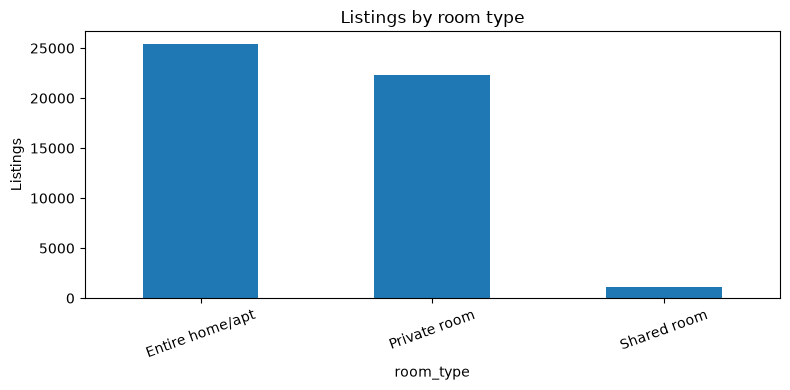

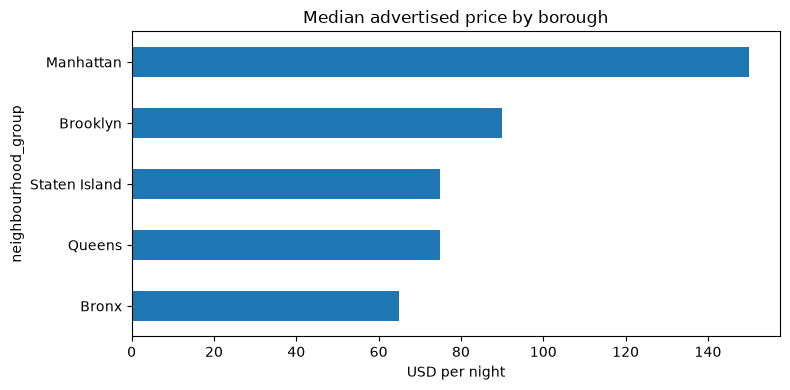

In [4]:
room = df.groupby('room_type').agg(listings=('id','count'), median_price=('price','median'), mean_price=('price','mean'), mean_reviews=('number_of_reviews','mean')).sort_values('listings', ascending=False)
borough = df.groupby('neighbourhood_group').agg(listings=('id','count'), median_price=('price','median'), mean_price=('price','mean'), mean_reviews=('number_of_reviews','mean'), median_availability=('availability_365','median')).sort_values('listings', ascending=False)
display(room); display(borough)
print('Price vs reviews correlation:', df[['price','number_of_reviews']].corr().iloc[0,1])
print('Price vs minimum nights correlation:', df[['price','minimum_nights']].corr().iloc[0,1])
print('Price vs availability correlation:', df[['price','availability_365']].corr().iloc[0,1])
fig, ax = plt.subplots(figsize=(8,4)); room['listings'].plot.bar(ax=ax); ax.set_title('Listings by room type'); ax.set_ylabel('Listings'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8,4)); borough['median_price'].sort_values().plot.barh(ax=ax); ax.set_title('Median advertised price by borough'); ax.set_xlabel('USD per night'); plt.tight_layout(); plt.show()

## Interpretation and cautions

Use medians as well as means because nightly prices are typically right-skewed. A correlation is descriptive and does not establish causation. `number_of_reviews` is not a direct measure of occupancy, and `last_review` is a snapshot field rather than a time series of all bookings. Latitude/longitude can be plotted to examine geographic clustering, but no external map or boundary data is joined.

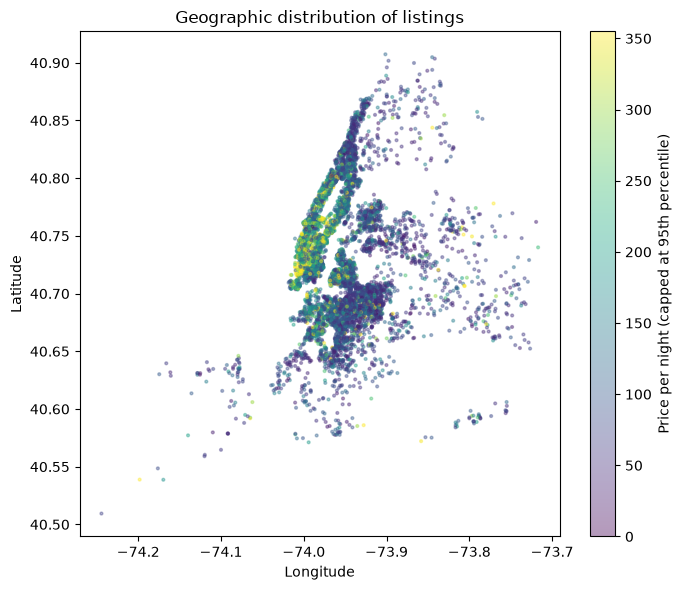

In [5]:
# Optional geographic view using only coordinates in the supplied file
sample = df.sample(min(8000, len(df)), random_state=42)
plt.figure(figsize=(7,6)); plt.scatter(sample['longitude'], sample['latitude'], c=sample['price'].clip(upper=df['price'].quantile(.95)), s=4, alpha=.4)
plt.colorbar(label='Price per night (capped at 95th percentile)'); plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.title('Geographic distribution of listings'); plt.tight_layout(); plt.show()
# Export cleaned data and summaries
Path('outputs').mkdir(exist_ok=True)
df.to_csv('outputs/airbnb_nyc_cleaned.csv', index=False)
room.to_csv('outputs/room_type_summary.csv'); borough.to_csv('outputs/borough_summary.csv')